# Customer Segmentation Analysis

## Project objective

This notebook uses **K-Means clustering** to explore groups of customers with similar demographic, household, purchasing, channel, and campaign-response characteristics. The business goal is to generate useful hypotheses for customer-focused marketing and further investigation.

This is an **unsupervised exploratory analysis**: there is no known segment label to predict, and a cluster is not a definitive customer identity or a causal explanation of behavior. The usefulness of any segment depends on appropriate feature preparation, validation, and interpretation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('data\customer-data.csv')
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [3]:
df.shape
#(2240, 29) its indicate that there are 2240 rows and 29 columns in the dataset.

(2240, 29)

## 1. Dataset and data preparation

The source file contains **2,240 customer records and 29 columns**. It combines customer profile fields (such as birth year, education, marital status, and income), household composition, product spending, purchase-channel activity, campaign acceptance indicators, and a response indicator. This makes it possible to explore both customer characteristics and observed behavior.

The columns represent different kinds of information and have very different units. Spending fields are monetary amounts, purchase and household fields are counts, campaign fields are binary indicators, and profile fields include categories. That mix is important: K-Means compares Euclidean distances, so encoding and scaling choices can strongly affect the result.

### Data quality checks

The inspection below checks data types, descriptive statistics, missingness, and the number of distinct values. In the supplied data, `Income` has **24 missing values (about 1.1%)**; the other columns are complete. The raw mean income is approximately **52,247**, while the maximum is **666,666**, so the distribution includes an extreme value that should be investigated before distance-based modeling. `Year_Birth` also includes 1893, a value that merits a plausibility check.

The notebook removes rows with missing values, leaving **2,216 customers**. This is a simple complete-case choice; the small number of removed rows limits the immediate loss, but missingness should still be checked for systematic patterns before treating this as representative.

In [4]:
df.info() #this function is used to get a concise summary of the DataFrame, including the number of non-null entries, data types, and memory usage.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


In [6]:
#checking for missing values in the dataset
for column in df.columns:
    temp = df[column].isnull().sum()
    if temp > 0:
        print(f"{column} has {temp} missing values")

Income has 24 missing values


In [7]:
df = df.dropna() #this function is used to remove any rows with missing values from the DataFrame. The inplace=True argument modifies the original DataFrame directly, rather than creating a new one.
print(len(df)) #this function is used to get the number of rows in the DataFrame after dropping the missing values.

2216


In [8]:
df.nunique() #this function is used to get the number of unique values in each column of the DataFrame.

ID                     2216
Year_Birth               59
Education                 5
Marital_Status            8
Income                 1974
Kidhome                   3
Teenhome                  3
Dt_Customer             662
Recency                 100
MntWines                776
MntFruits               158
MntMeatProducts         554
MntFishProducts         182
MntSweetProducts        176
MntGoldProds            212
NumDealsPurchases        15
NumWebPurchases          15
NumCatalogPurchases      14
NumStorePurchases        14
NumWebVisitsMonth        16
AcceptedCmp3              2
AcceptedCmp4              2
AcceptedCmp5              2
AcceptedCmp1              2
AcceptedCmp2              2
Complain                  2
Z_CostContact             1
Z_Revenue                 1
Response                  2
dtype: int64

In [9]:
parts = df["Dt_Customer"].str.split("-", n=3, expand=True) #this function is used to split the "Dt_Customer" column into three separate columns based on the "-" delimiter. The n=3 argument specifies that the split should occur at most 3 times, resulting in four columns. The expand=True argument indicates that the result should be a DataFrame with separate columns for each split part.
df["day"] = parts[0].astype(int) #this function is used to convert the "day" column to an integer data type.
df["month"] = parts[1].astype(int) #this function is used to convert the "month" column to an integer data type.
df["year"] = parts[2].astype(int) #this function is used to convert

In [10]:
df.drop(['Z_CostContact', 'Z_Revenue', 'Dt_Customer'], axis=1, inplace=True) #this function is used to remove the "Z_CostContact" and "Z_Revenue" columns from the DataFrame. The axis=1 argument specifies that the operation should be performed on columns, and inplace=True modifies the original DataFrame directly.

## 2. Exploratory data analysis

The visualizations summarize the two categorical profile fields and compare campaign response counts across their categories. In this dataset, **Education** is led by Graduation (1,127 customers, about 50%), followed by PhD (486, about 22%) and Master (370, about 17%). The largest marital-status groups are Married (864, about 39%) and Together (580, about 26%); smaller values such as Alone, Absurd, and YOLO should be treated cautiously because they represent very few records.

The response charts show counts, not normalized within-category response rates. A larger bar can therefore reflect a larger category rather than a stronger likelihood to respond. For a business comparison, calculate the response proportion within each group and include uncertainty for small groups. These plots describe this dataset; they do not establish why customers responded.

### Feature preparation and correlation

The date string is split into day, month, and year components, then the original date and two constant-valued fields (`Z_CostContact` and `Z_Revenue`) are removed. Splitting a date into three numeric parts does not directly measure customer tenure; day and month also introduce arbitrary numeric distances. A more meaningful feature would be tenure calculated from a documented reference date.

The object-valued fields are encoded before the correlation heatmap and clustering. `LabelEncoder` assigns integer codes to categories, but those codes imply an ordering and spacing that the categories do not have. In particular, Education and Marital_Status are nominal categories, so interpreting their encoded correlations or Euclidean distances as meaningful requires caution. The `ID` field is also still present at this point; it is an identifier, not customer behavior, and should normally be excluded from clustering.

In [11]:
floats, objects = [], []
for col in df.columns:
    if df[col].dtype == object:
        objects.append(col)
    elif df[col].dtype == float:
        floats.append(col)

print(objects)
print(floats)

['Education', 'Marital_Status']
['Income']


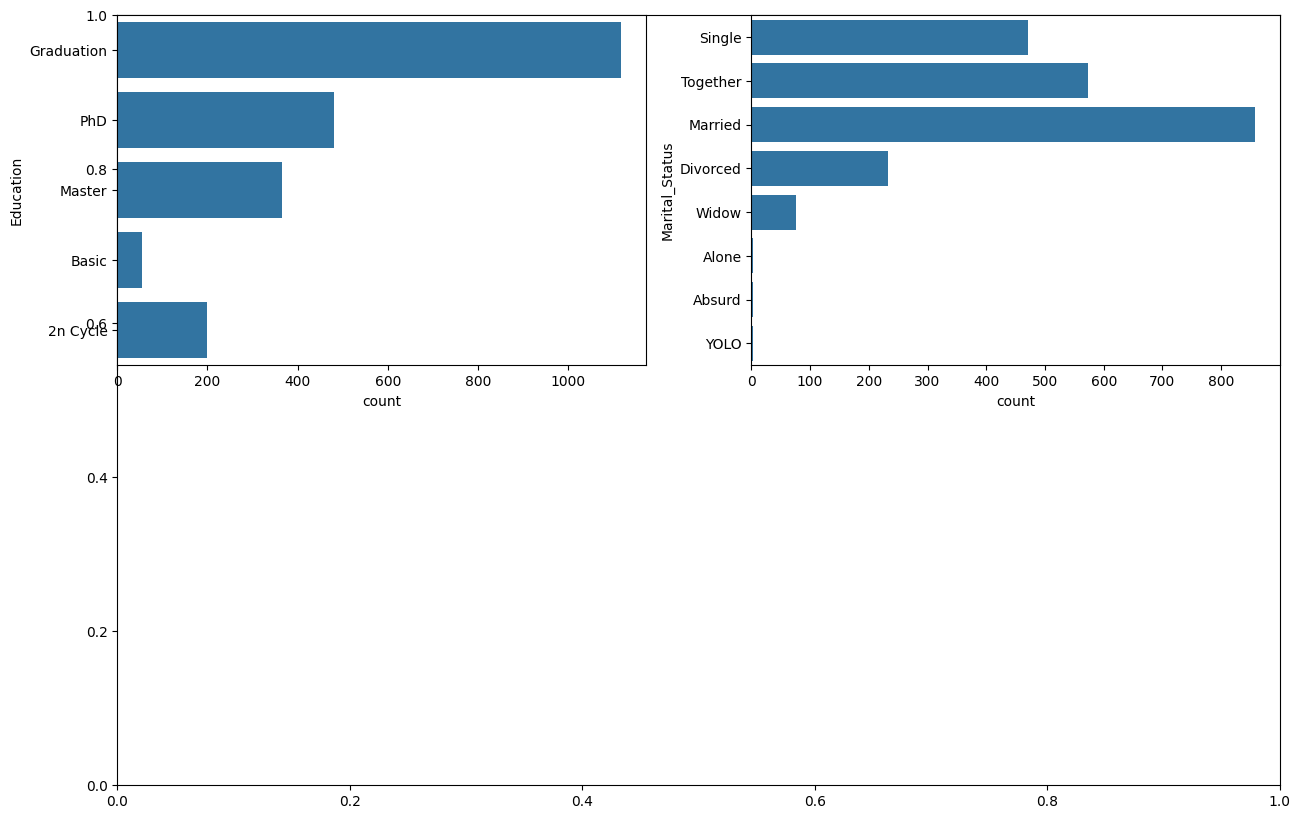

In [12]:
plt.subplots(figsize=(15, 10))
for i, col in enumerate(objects):
    plt.subplot(2, 2, i + 1)
    sb.countplot(df[col])
plt.show()

In [14]:
df['Marital_Status'].value_counts()

Marital_Status
Married     857
Together    573
Single      471
Divorced    232
Widow        76
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

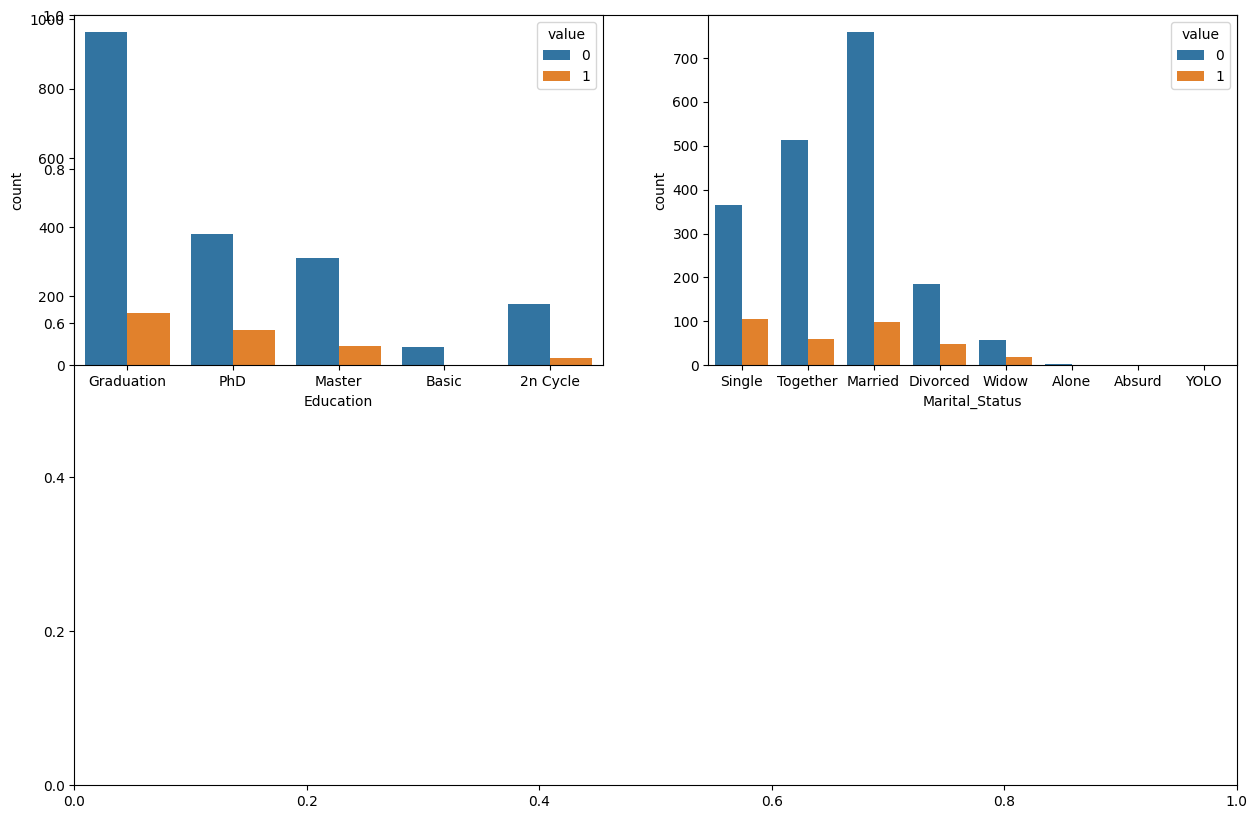

In [15]:
plt.subplots(figsize=(15, 10))
for i, col in enumerate(objects):
    plt.subplot(2, 2, i + 1)

    df_melted = df.melt(id_vars=[col], value_vars=['Response'], var_name='hue')
    sb.countplot(x=col, hue='value', data=df_melted)
plt.show()

In [16]:
for col in df.columns:
    if df[col].dtype == object:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col])

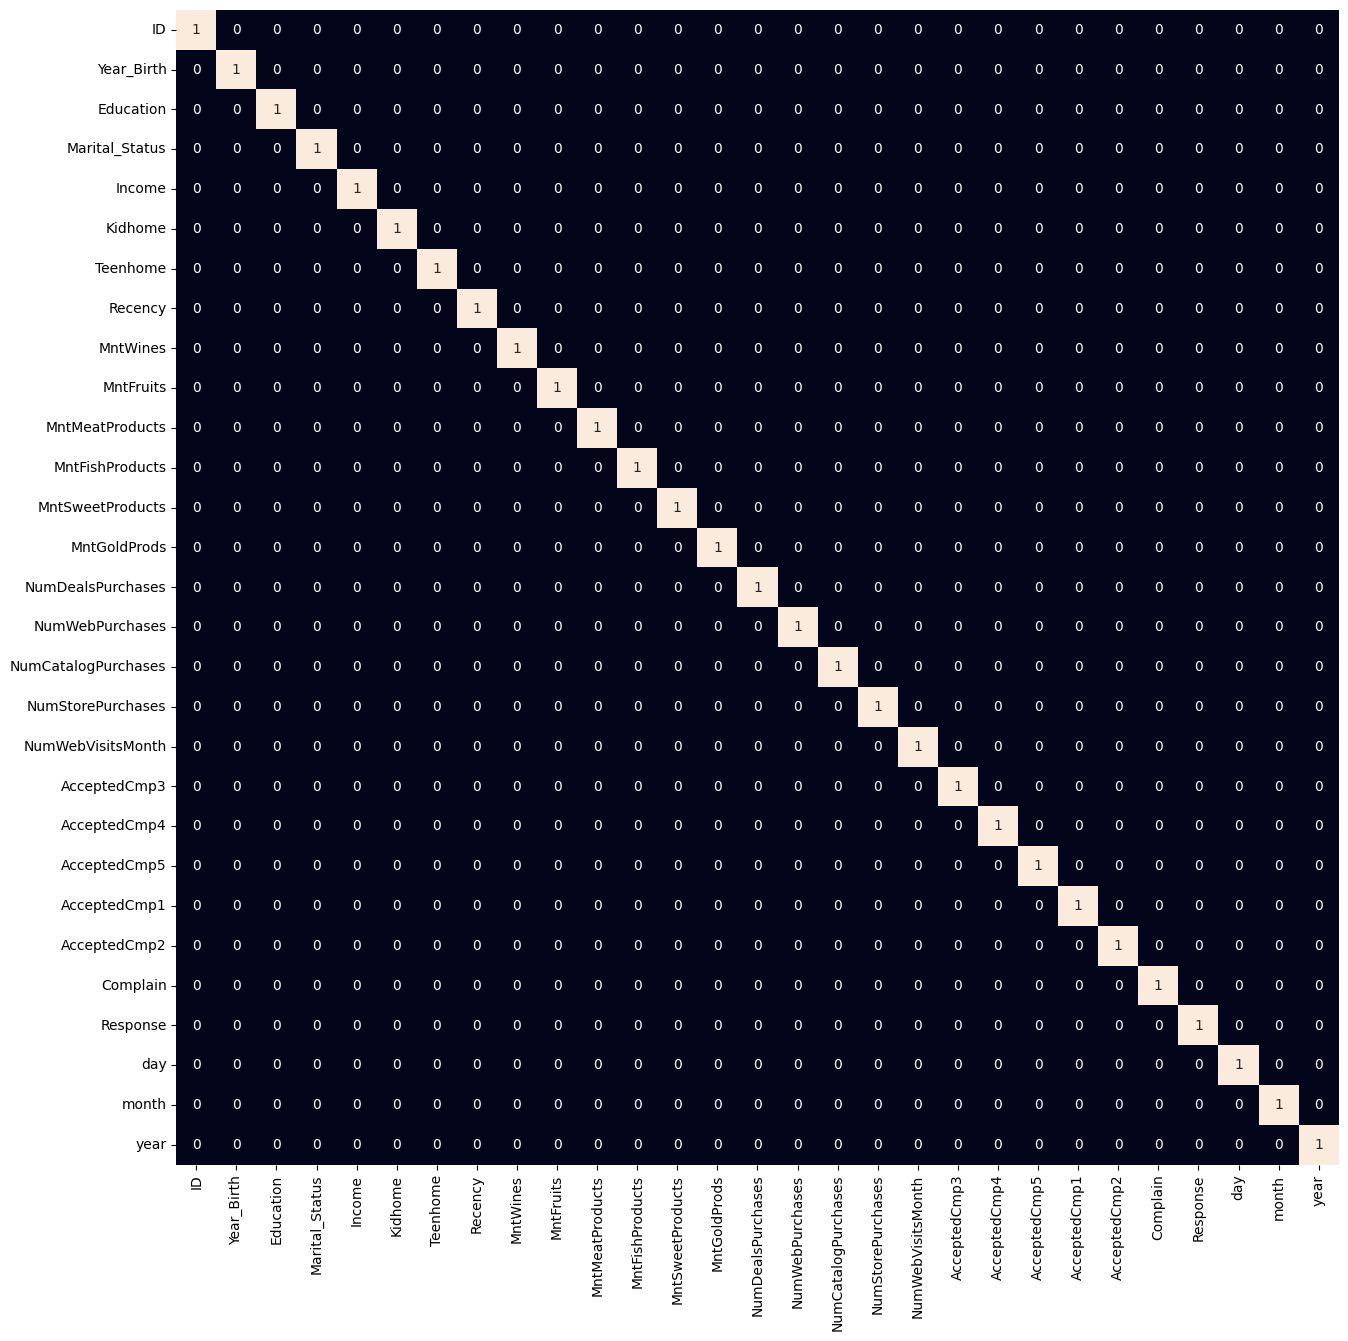

In [17]:
plt.figure(figsize=(15, 15))
sb.heatmap(df.corr() > 0.8, annot=True, cbar=False)
plt.show()

## 3. Feature scaling and 2D exploration

`StandardScaler` is used to create `data`, which standardizes each feature to comparable scale. However, the subsequent t-SNE and K-Means cells currently receive `df`, not `data`. As a result, the calculated standardized matrix is not used by either analysis. With unscaled features, large-valued variables such as Income, spending, and the customer ID can dominate Euclidean distances; this materially limits the interpretability of both the embedding and clusters.

The t-SNE scatterplot is intended as a visual summary in two dimensions. It is an exploratory projection, not a clustering algorithm or a proof that naturally distinct groups exist. Its geometry can change with preprocessing and t-SNE settings, so assess it only after using an appropriate feature matrix and do not infer business meaning from the axes.

In [18]:
scaler = StandardScaler()
data = scaler.fit_transform(df)

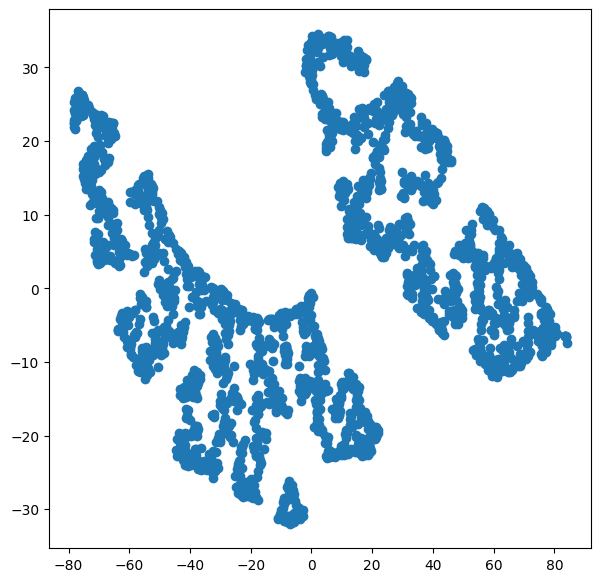

In [19]:
from sklearn.manifold import TSNE
model = TSNE(n_components=2, random_state=0)
tsne_data = model.fit_transform(df)
plt.figure(figsize=(7, 7))
plt.scatter(tsne_data[:, 0], tsne_data[:, 1])
plt.show()

## 4. Selecting a cluster count

The elbow method compares K-Means **inertia** (the within-cluster sum of squared distances) across candidate values of *k*. Inertia always decreases as more clusters are added, so the useful signal is a clear bend where further clusters yield diminishing improvement - not simply the lowest plotted value.

For the current, unscaled feature matrix, the curve decreases steeply at first and then continues to decline without an unambiguous single elbow. The choice of **five clusters** below is therefore a provisional modeling choice rather than a result established by the curve. Since feature scales and encodings are not suitable yet, this elbow plot should be recalculated after improving preprocessing.

In [20]:
error = []
for n_clusters in range(1, 21):
    model = KMeans(init='k-means++',
                   n_clusters=n_clusters,
                   max_iter=500,
                   random_state=22)
    model.fit(df)
    error.append(model.inertia_)

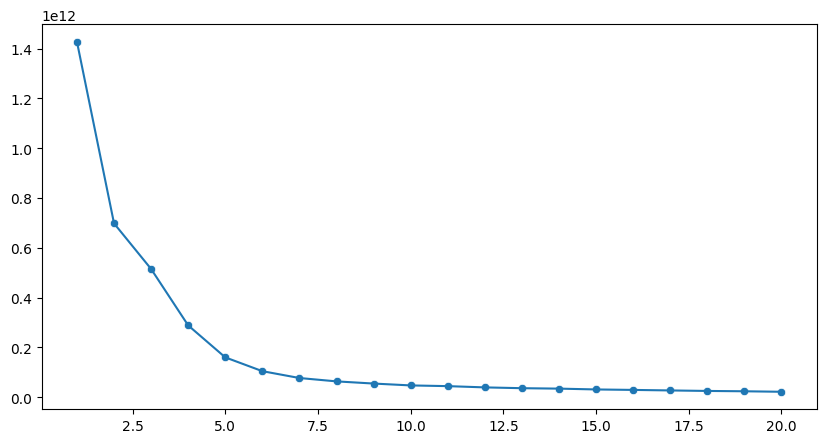

In [21]:
plt.figure(figsize=(10, 5))
sb.lineplot(x=range(1, 21), y=error)
sb.scatterplot(x=range(1, 21), y=error)
plt.show()

## 5. Five-cluster result and interpretation

The final cell assigns each customer one of five K-Means labels, then colors the t-SNE points by that label. A label is only an identifier: cluster 0 is not inherently better, more valuable, or more important than cluster 1. Read the plot together with the cluster sizes and feature profiles, not as a standalone business conclusion.

In [22]:
model = KMeans(init='k-means++',
               n_clusters=5,
               max_iter=500,
               random_state=22)
segments = model.fit_predict(df)

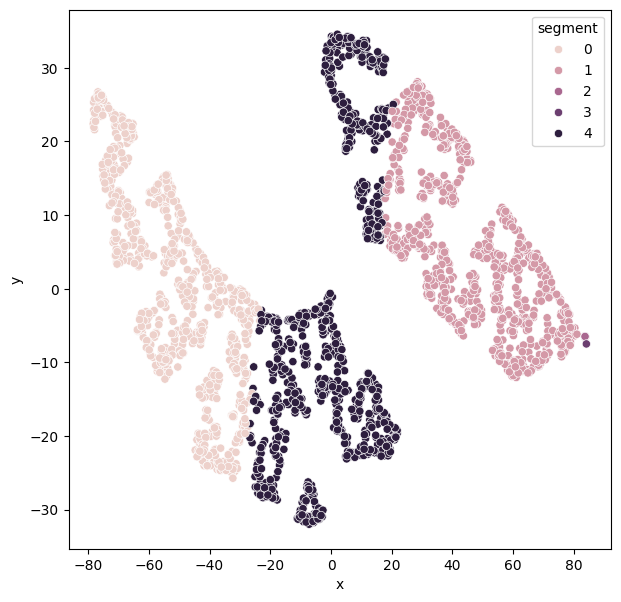

In [23]:
plt.figure(figsize=(7, 7))

df_tsne = pd.DataFrame({'x': tsne_data[:, 0], 'y': tsne_data[:, 1], 'segment': segments})

sb.scatterplot(x='x', y='y', hue='segment', data=df_tsne)
plt.show()

### Observed segment profile

Re-running the notebook's current five-cluster configuration on the supplied data produced the following sizes and average profiles. Segment numbers are arbitrary identifiers; small differences may occur across scikit-learn versions because `n_init` is not explicitly set.

| Segment | Customers | Share | Mean income | Mean wine spend | Mean meat spend | Initial observation |
|:--|--:|--:|--:|--:|--:|:--|
| 0 | 719 | 32.4% | 27,992 | 29 | 25 | Lower average income and low average spend in these product categories. |
| 1 | 717 | 32.4% | 75,511 | 623 | 386 | Higher average income and substantially higher wine and meat spend. |
| 2 | 7 | 0.3% | 158,024 | 29 | 708 | Very small group with high average meat spend; too small to treat as a stable segment without validation. |
| 3 | 1 | <0.1% | 666,666 | 9 | 18 | A singleton aligned with the extreme income value; investigate the record before interpreting it. |
| 4 | 772 | 34.8% | 51,476 | 270 | 91 | Largest group, with middle-range average income and product spend. |

These profiles are descriptive summaries of this particular run, not validated customer personas. The singleton and seven-customer group show that the current model isolates extreme observations instead of producing five comparably sized, clearly actionable segments. The very large income outlier, unscaled numeric features, encoded nominal categories, and inclusion of `ID` can all influence the distances and likely contribute to this result. Treat apparent differences between the larger groups as exploratory signals only.

### Conclusion and recommended next iteration

The notebook demonstrates a complete exploratory workflow - from data inspection through K-Means and a two-dimensional visualization - but the current clusters should **not yet be used to target customers or make business claims**. To make the segmentation more defensible:

1. Exclude `ID` and investigate extreme or implausible values (including the income maximum and earliest birth year) using documented data-quality rules.
2. Encode nominal categories with an approach that does not impose a false order, and scale the actual feature matrix passed to both K-Means and t-SNE. Consider separate, justified handling for binary indicators and skewed spending fields.
3. Represent customer-registration dates as a meaningful tenure feature using an explicit reference date rather than raw day/month/year parts.
4. Re-evaluate candidate values of *k* with multiple diagnostics (such as silhouette score and cluster-size stability) alongside the elbow curve; also check whether the resulting groups are interpretable and useful to the business.
5. Profile validated clusters on the original, human-readable columns, including normalized campaign-response rates, and document the limitations and intended use of any proposed customer personas.

Until those checks are completed, the main takeaway is methodological: **preprocessing choices define the distances that K-Means sees, and those distances define the segments.**